In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [70]:
df = pd.read_csv('titanic.csv')  # importamos los datos

## EDA

In [71]:
display(df.head())  # mostramos las primeras filas del DataFrame

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [72]:
df.drop(['Name', 'Fare','Siblings/Spouses Aboard','Parents/Children Aboard'], axis=1, inplace=True)  # eliminamos columnas no necesarias

In [73]:
df.columns = ["Survived", "Pclass","Sex", "Age"]

In [74]:
df.head()  # mostramos las primeras filas del dataset

,Survived,Pclass,Sex,Age
0,0,3,male,22.0
1,1,1,female,38.0
2,1,3,female,26.0
3,1,1,female,35.0
4,0,3,male,35.0


In [75]:
df = pd.get_dummies(df, columns=["Sex"], drop_first=True).astype(int)  # convertimos la columna 'Sex' a variables dummy

In [76]:
df.head()

,Survived,Pclass,Age,Sex_male
0,0,3,22,1
1,1,1,38,0
2,1,3,26,0
3,1,1,35,0
4,0,3,35,1


In [77]:
df.rename(columns={"Sex_male": "Sex"}, inplace=True)  # renombramos la columna 'Sex_male' a 'Male' 

In [78]:
df.head()  # mostramos las primeras filas del dataset

,Survived,Pclass,Age,Sex
0,0,3,22,1
1,1,1,38,0
2,1,3,26,0
3,1,1,35,0
4,0,3,35,1


In [79]:
df.duplicated().any()  # verificamos si hay filas duplicadas

np.True_

In [80]:
df.drop_duplicates(inplace=True)  # eliminamos filas duplicadas

In [81]:
df.duplicated().any()  # verificamos nuevamente si hay filas duplicadas

np.False_

## Entrenamiento

In [82]:
x = df.drop("Survived", axis=1)  # definimos las variables independientes
y = df["Survived"]  # definimos la variable dependiente

In [83]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.3, random_state= 42)

In [84]:
arbol = DecisionTreeClassifier(max_depth=2, random_state=42)  # creamos el modelo de árbol de decisión
arbol.fit(x_train, y_train)  # entrenamos el modelo

DecisionTreeClassifier(max_depth=2, random_state=42)

In [85]:
y_pred = arbol.predict(x_test)  # hacemos predicciones sobre el conjunto de prueba
accuracy = accuracy_score(y_test, y_pred)  # calculamos la precisión del modelo
print(f"Precisión del modelo: {accuracy:.2f}")  # mostramos la precisión del modelo

Precisión del modelo: 0.76


<Axes: xlabel='None'>

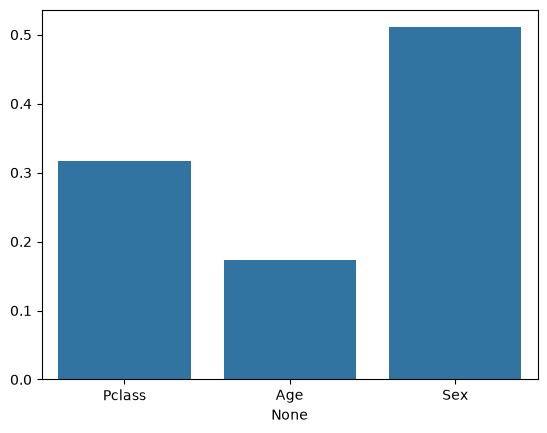

In [86]:
importancia = arbol.feature_importances_  # obtenemos la importancia de cada característica
columnas = x.columns  # obtenemos los nombres de las columnas

sns.barplot(x=columnas, y=importancia)  # creamos un gráfico de barras para mostrar la importancia de cada característica